In [3]:

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("SciPy version:", scipy.__version__)
print("Python libraries imported successfully!")


NumPy version: 2.4.6
Pandas version: 3.0.6
SciPy version: 1.17.1
Python libraries imported successfully!


In [4]:
# Project root: one level above the notebooks folder
PROJECT_ROOT = Path.cwd().parent #gets the current working directory, moves one folder upwards to find parent

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "figures",
    "results",
    "references"
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir( #creates the required directories.
        parents=True,
        exist_ok=True #prevents an error if a folder already
    )

print("Project folders created successfully!")
print("Project location:", PROJECT_ROOT)


Project folders created successfully!
Project location: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson



# PH3043 — Reconstruction of the Z-Boson Mass from CERN Collision Data

## Notebook 01: Initial Data Exploration

### 1. Objective

The objective of this notebook is to explore a CERN CMS dimuon collision dataset, understand the physical variables, examine data quality, and prepare the data for invariant-mass reconstruction.

### 2. Physical Background

The **Z boson** is an electrically neutral elementary particle that mediates the weak interaction. One of its possible decay channels produces a muon and an antimuon:

$$
Z^0 \rightarrow \mu^+ + \mu^-
$$

The muon ($\mu^-$) and antimuon ($\mu^+$) carry opposite electric charges.

By measuring the energies and momenta of the two muons, we can reconstruct the **invariant mass** of the muon pair.

The invariant mass is calculated using:

$$
M_{\mu\mu}^2 c^4 =
(E_1+E_2)^2
-
c^2\left|\vec{p}_1+\vec{p}_2\right|^2
$$

Therefore,

$$
M_{\mu\mu} =
\frac{1}{c^2}
\sqrt{
(E_1+E_2)^2
-
c^2\left|\vec{p}_1+\vec{p}_2\right|^2
}
$$

where:

- $M_{\mu\mu}$ = invariant mass of the muon pair
- $E_1,E_2$ = energies of the two muons
- $\vec{p}_1,\vec{p}_2$ = momentum vectors of the two muons
- $c$ = speed of light

In **natural units**, where $c=1$, this simplifies to:

$$
\boxed{
M_{\mu\mu} =
\sqrt{
(E_1+E_2)^2
-
\left|\vec{p}_1+\vec{p}_2\right|^2
}
}
$$

The reconstructed invariant-mass distribution is expected to show a resonance near the Z-boson mass of approximately:

$$
M_Z \approx 91.19\ \mathrm{GeV}/c^2
$$

### 3. Analysis Approach

The analysis will be carried out in Python using scientific computing libraries.

**Step 1 — Load and inspect the dataset**

- Import the required Python libraries.
- Load the CERN CMS dimuon collision dataset.
- Examine its structure, dimensions, and column names.

**Step 2 — Understand the physical variables**

- Identify the muon energy and momentum variables.
- Determine their physical meanings and units.
- Understand how the recorded quantities relate to particle four-momentum.

**Step 3 — Examine data quality**

- Check for missing values and duplicate records.
- Identify invalid or nonphysical measurements.
- Examine relevant event-quality and selection criteria.

**Step 4 — Reconstruct the invariant mass**

- Extract the required muon kinematic quantities.
- Calculate the invariant mass for each muon pair.
- Check that the calculations use consistent units.

**Step 5 — Visualize and analyze the results**

- Plot the reconstructed invariant-mass distribution.
- Identify the Z-boson resonance.
- Compare the reconstructed mass with the accepted Z-boson mass.
- Investigate possible sources of uncertainty.

### 4. Expected Outcome

By the end of this analysis, the dataset structure and physical variables should be understood, basic data-quality checks should be completed, and the dimuon invariant-mass distribution should be reconstructed.

The main goal is to identify the Z-boson resonance using real CERN collision data and understand how experimentally measured particle momenta can be used to reconstruct the mass of a short-lived particle.


In [7]:
# Check where Jupyter is currently running
CURRENT_DIR = Path.cwd().resolve()

# Find the main project directory
if CURRENT_DIR.name == "PH3043_ZBoson":
    PROJECT_ROOT = CURRENT_DIR
elif CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise RuntimeError(
        "Please run this notebook inside "
        "PH3043_ZBoson/notebooks"
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"

print("Current directory:", CURRENT_DIR)
print("Project root:", PROJECT_ROOT)
print("Raw data folder:", DATA_DIR)

print("\nProject folder exists:",
      PROJECT_ROOT.is_dir())
print("Data folder exists:",
      DATA_DIR.is_dir())


Current directory: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\notebooks
Project root: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson
Raw data folder: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\data\raw

Project folder exists: True
Data folder exists: True


In [9]:
#Finding the CERN data set

# List downloaded CSV files
csv_files = sorted(DATA_DIR.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print("File:", file.name)
    print("Size (MB):",
          round(file.stat().st_size / 1_000_000, 2))


CSV files found: 1
File: Dimuon_SingleMu.csv
Size (MB): 11.81


In [11]:
# Load the primary SingleMu dataset explicitly.
# Both SingleMu and DoubleMu are intentionally present in data/raw.
singlemu_file = DATA_DIR / "Dimuon_SingleMu.csv"
if not singlemu_file.is_file():
    raise FileNotFoundError(f"Required CERN file not found: {singlemu_file}")

df = pd.read_csv(singlemu_file)
print("Primary dataset:", singlemu_file.name)
print("Dataset dimensions:", df.shape)
print("Available variables:", list(df.columns))
display(df.head())


Dataset dimensions: (83761, 21)


,Run,Event,type1,Q1,pt1,eta1,phi1,E1,px1,py1,...,type2,Q2,pt2,eta2,phi2,E2,px2,py2,pz2,M
0,166699,835716681,G,1,4.2116,2.2366,-0.4849,19.9382,3.7261,-1.9631,...,T,-1,1.2556,2.2683,-1.4488,6.1319,0.1528,-1.2463,6.0011,2.1330
1,166699,836133459,G,-1,2.1479,-2.0159,-2.7753,8.2066,-2.0055,-0.7692,...,G,1,19.5453,-1.0826,-0.3408,32.1613,18.4210,-6.5332,-25.5406,13.6786
2,166699,836165498,G,1,21.0732,1.5948,-1.1137,54.0560,9.2997,-18.9102,...,T,-1,2.3864,1.5352,-1.7388,5.7968,-0.3991,-2.3528,5.2818,4.3813
3,166699,836249706,G,1,18.5889,1.6422,1.1923,49.8180,6.8688,17.2734,...,G,-1,1.8721,1.9704,1.6393,6.8459,-0.1281,1.8678,6.5841,3.2587
4,166699,835608783,G,-1,11.8194,0.8711,-1.5811,16.5947,-0.1214,-11.8187,...,T,1,0.9408,2.0107,-1.6559,3.5779,-0.0799,-0.9374,3.4504,4.0171


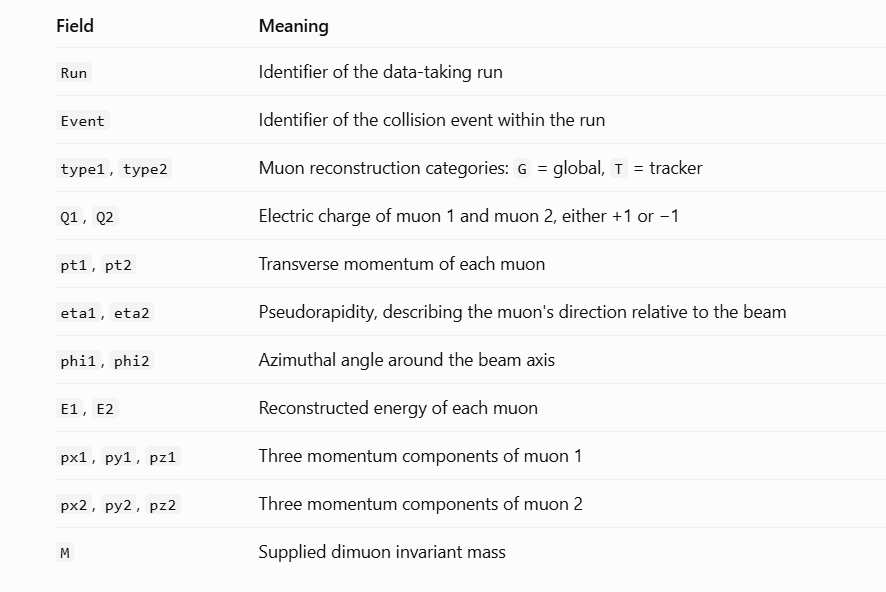

## 2. Initial Data Quality Assessment

In [13]:

# Basic dataset quality assessment

print("Total events:", len(df))
print("Total variables:", len(df.columns))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate collision identifiers
duplicates = df.duplicated(
    subset=["Run", "Event"]
).sum()

print("\nDuplicate Run-Event pairs:", duplicates)

# Check charge combinations
print("\nMuon charge combinations:")
print(
    df.groupby(["Q1", "Q2"]).size()
)

# Check reconstruction types
print("\nMuon reconstruction types:")
print(
    df.groupby(["type1", "type2"]).size()
)


Total events: 83761
Total variables: 21

Missing values:
Run      0
Event    0
type1    0
Q1       0
pt1      0
eta1     0
phi1     0
E1       0
px1      0
py1      0
pz1      0
type2    0
Q2       0
pt2      0
eta2     0
phi2     0
E2       0
px2      0
py2      0
pz2      0
M        0
dtype: int64

Duplicate Run-Event pairs: 0

Muon charge combinations:
Q1  Q2
-1   1    41147
 1  -1    42614
dtype: int64

Muon reconstruction types:
type1  type2
G      G        34742
       T        49019
dtype: int64


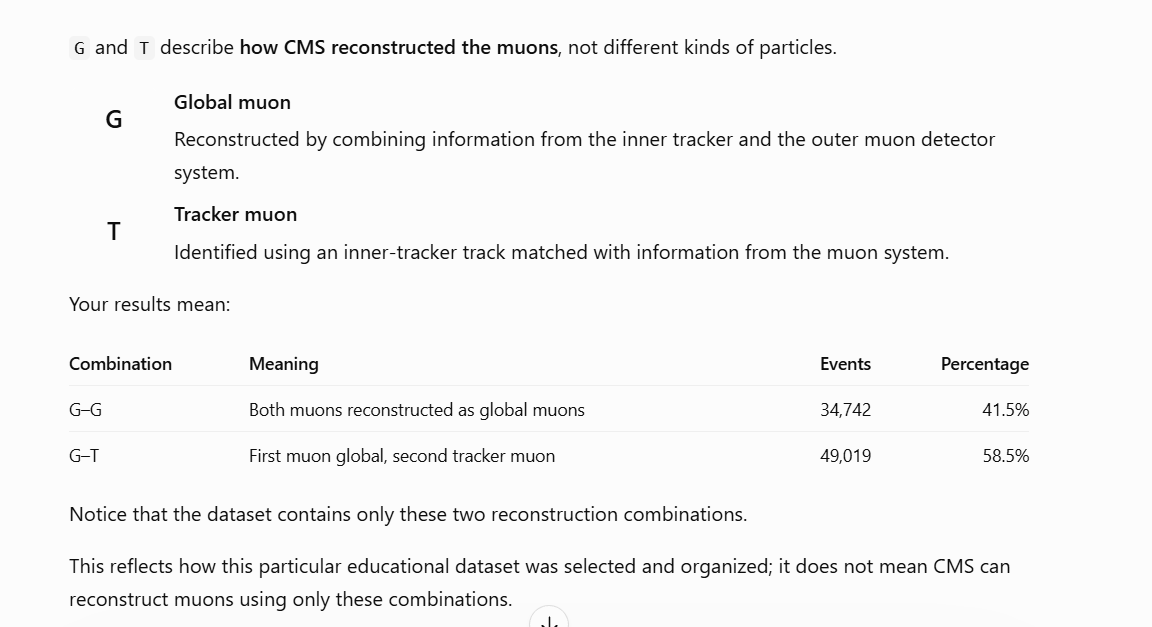

Reconstruction types: Different reconstruction methods can have different measurement resolutions and selection properties. Checking them helps us understand the composition of the dataset and investigate possible differences in reconstructed masses.

## 3. Exploratory Analysis of Muon Properties

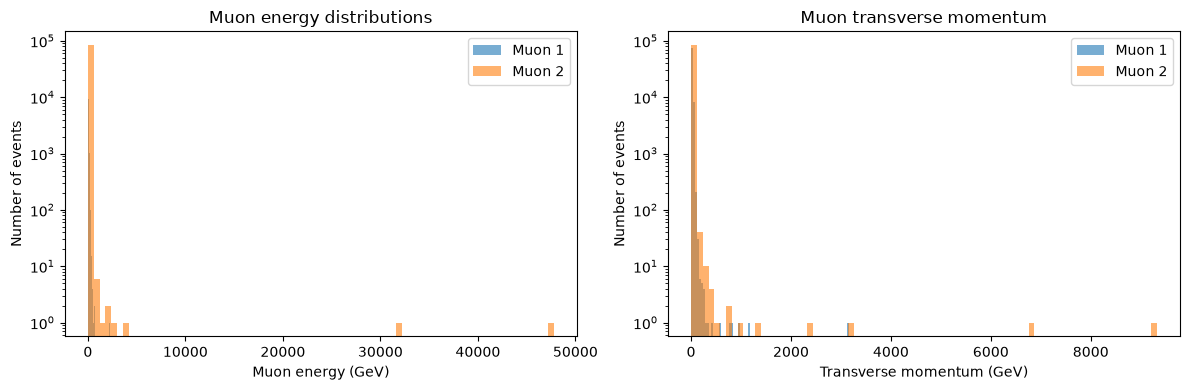

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Muon energy distributions
axes[0].hist(
    df["E1"], bins=80,
    alpha=0.6, label="Muon 1"
)
axes[0].hist(
    df["E2"], bins=80,
    alpha=0.6, label="Muon 2"
)

axes[0].set_xlabel("Muon energy (GeV)")
axes[0].set_ylabel("Number of events")
axes[0].set_title("Muon energy distributions")
axes[0].legend()
axes[0].set_yscale("log")

# Transverse momentum distributions
axes[1].hist(
    df["pt1"], bins=80,
    alpha=0.6, label="Muon 1"
)
axes[1].hist(
    df["pt2"], bins=80,
    alpha=0.6, label="Muon 2"
)

axes[1].set_xlabel("Transverse momentum (GeV)")
axes[1].set_ylabel("Number of events")
axes[1].set_title("Muon transverse momentum")
axes[1].set_yscale("log")
axes[1].legend()

plt.tight_layout()
plt.show()


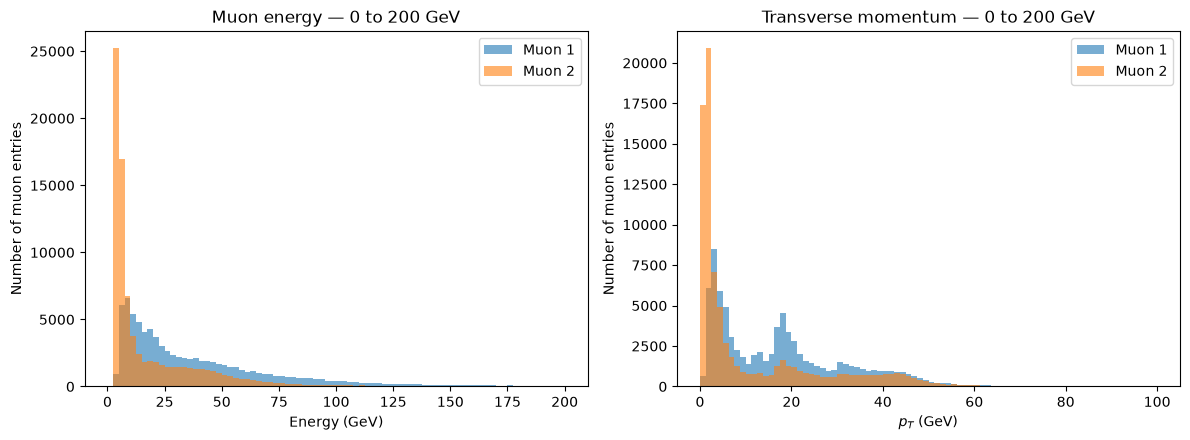

In [67]:
#o- 200GeV range

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Muon energies
axes[0].hist(
    df["E1"], bins=80, range=(0, 200),
    alpha=0.6, label="Muon 1"
)
axes[0].hist(
    df["E2"], bins=80, range=(0, 200),
    alpha=0.6, label="Muon 2"
)
axes[0].set_title("Muon energy — 0 to 200 GeV")
axes[0].set_xlabel("Energy (GeV)")
axes[0].set_ylabel("Number of muon entries")
axes[0].legend()

# Muon transverse momenta
axes[1].hist(
    df["pt1"], bins=80, range=(0, 100),
    alpha=0.6, label="Muon 1"
)
axes[1].hist(
    df["pt2"], bins=80, range=(0, 100),
    alpha=0.6, label="Muon 2"
)
axes[1].set_title("Transverse momentum — 0 to 200 GeV")
axes[1].set_xlabel(r"$p_T$ (GeV)")
axes[1].set_ylabel("Number of muon entries")
axes[1].legend()

plt.tight_layout()
plt.show()


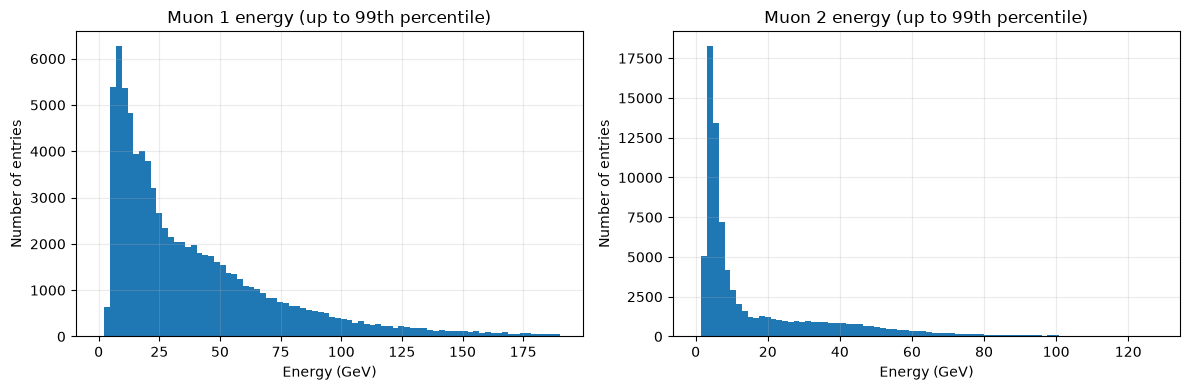

In [16]:
#investigating extreme values
# Examine the muon energy distributions more closely

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, title in zip(
    axes,
    ["E1", "E2"],
    ["Muon 1 energy", "Muon 2 energy"]
):
    upper = df[col].quantile(0.99)

    ax.hist(df[col], bins=80, range=(0, upper))
    ax.set_xlabel("Energy (GeV)")
    ax.set_ylabel("Number of entries")
    ax.set_title(f"{title} (up to 99th percentile)")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 4. Kinematic Consistency Checks

Before reconstructing the dimuon invariant mass, we verify
whether the reported transverse momentum agrees with the
momentum components recorded for each muon.

The transverse momentum is defined as:

$$
p_T = \sqrt{p_x^2 + p_y^2}
$$

Differences between the reported and calculated values will
be investigated before applying any selection criteria.

In [20]:

# Calculate transverse momentum independently

df["pt1_calc"] = np.sqrt(df["px1"]**2 + df["py1"]**2)
df["pt2_calc"] = np.sqrt(df["px2"]**2 + df["py2"]**2)

# Absolute differences from CERN-provided values
df["pt1_diff"] = abs(df["pt1_calc"] - df["pt1"])
df["pt2_diff"] = abs(df["pt2_calc"] - df["pt2"])

print("Muon 1 transverse momentum difference:")
print(df["pt1_diff"].describe())

print("\nMuon 2 transverse momentum difference:")
print(df["pt2_diff"].describe())

# Examine the events with the largest discrepancies
display(
    df.nlargest(5, "pt1_diff")[
        ["Run", "Event", "pt1",
         "pt1_calc", "pt1_diff", "px1", "py1"]
    ]
)


Muon 1 transverse momentum difference:
count    83761.000000
mean         0.190404
std         13.232118
min          0.000000
25%          0.000014
50%          0.000031
75%          0.000054
max       3148.807851
Name: pt1_diff, dtype: float64

Muon 2 transverse momentum difference:
count    83761.000000
mean         0.053959
std         11.026824
min          0.000000
25%          0.000014
50%          0.000030
75%          0.000050
max       3183.062720
Name: pt2_diff, dtype: float64


,Run,Event,pt1,pt1_calc,pt1_diff,px1,py1
42227,166782,478331775,3161.4300,12.622149,3148.807851,-11.6885,4.7642
13062,166950,1050544228,1179.6800,15.204122,1164.475878,14.3716,-4.9621
78248,167284,1366279473,950.6280,1.779737,948.848263,-0.6196,-1.6684
81932,163738,123780029,790.8200,28.783889,762.036111,-24.2832,15.4544
41571,170896,58584445,15.8391,670.261366,654.422266,291.4700,-603.5690


## 5. Transverse Momentum Consistency Assessment

The transverse momenta were independently reconstructed using:

$$
p_T = \sqrt{p_x^2 + p_y^2}
$$

Most events showed very small discrepancies between the
calculated and CERN-provided transverse momenta. However,
some events exhibited much larger differences.

The following analysis quantifies these discrepancies
and identifies events requiring further investigation.

In [69]:
#Identify how many event are unconsistence

# Quantify discrepancies in transverse momentum

# Threshold for investigation, not a final physics cut
tolerance = 0.01  # GeV #10MeV

bad_pt1 = df["pt1_diff"] > tolerance
bad_pt2 = df["pt2_diff"] > tolerance

bad_event = bad_pt1 | bad_pt2 #logical or operator

print("Total events:", len(df))

print("Muon 1 discrepancies:", bad_pt1.sum())
print("Muon 2 discrepancies:", bad_pt2.sum())

print("Events with at least one discrepancy:",
      bad_event.sum())

print("Percentage affected:",
      round(100 * bad_event.mean(), 4), "%")

# Inspect the largest discrepancies
columns = [
    "Run", "Event",
    "pt1", "pt1_calc", "pt1_diff",
    "pt2", "pt2_calc", "pt2_diff"
]

display(
    df.loc[bad_event, columns]
      .sort_values("pt1_diff", ascending=False)
      .head(10)
)


Total events: 83761
Muon 1 discrepancies: 3360
Muon 2 discrepancies: 887
Events with at least one discrepancy: 4124
Percentage affected: 4.9235 %


,Run,Event,pt1,pt1_calc,pt1_diff,pt2,pt2_calc,pt2_diff
42227,166782,478331775,3161.4300,12.622149,3148.807851,1.6804,1.680355,0.000045
13062,166950,1050544228,1179.6800,15.204122,1164.475878,0.7636,0.763655,0.000055
78248,167284,1366279473,950.6280,1.779737,948.848263,4.1883,4.188280,0.000020
81932,163738,123780029,790.8200,28.783889,762.036111,3.5798,3.579781,0.000019
41571,170896,58584445,15.8391,670.261366,654.422266,2.5367,2.536689,0.000011
12724,166950,1034799867,17.8258,578.070011,560.244211,3.2646,3.264687,0.000087
801,166699,874169309,560.3860,41.138730,519.247270,16.3868,4.900424,11.486376
32313,167102,312254576,30.9928,420.624320,389.631520,1.6978,1.697775,0.000025
3555,171897,314985262,409.8720,72.746449,337.125551,57.3815,57.381498,0.000002
64768,171178,57001878,280.0690,14.722815,265.346185,4.3205,4.320503,0.000003


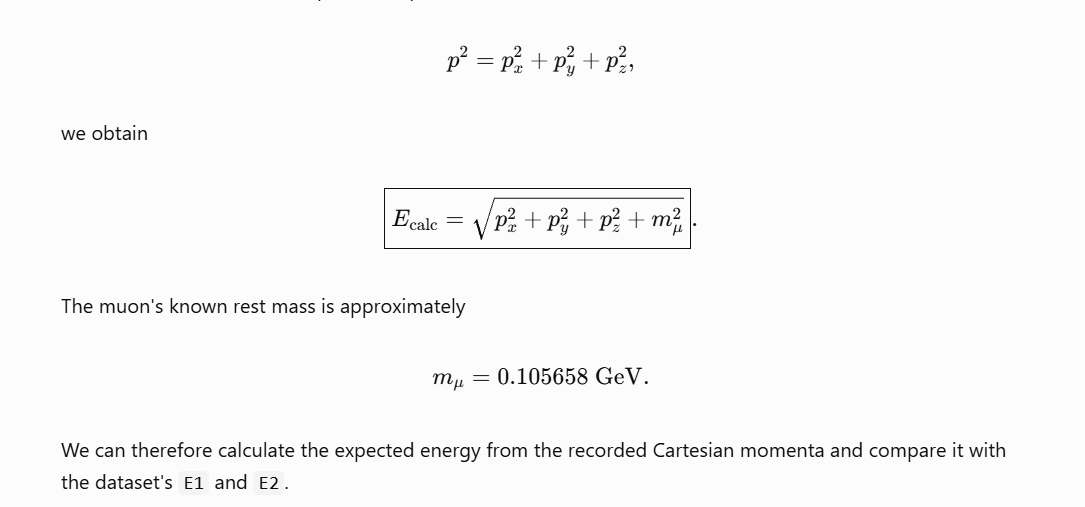

In [25]:
#Check whether these events also violate relativistic energy–momentum consistency

# Relativistic energy-momentum consistency

muon_mass = 0.105658  # GeV

for i in [1, 2]:
    p_squared = (
        df[f"px{i}"]**2
        + df[f"py{i}"]**2
        + df[f"pz{i}"]**2
    )

    df[f"E{i}_calc"] = np.sqrt(
        p_squared + muon_mass**2
    )

    df[f"E{i}_diff"] = abs(
        df[f"E{i}"] - df[f"E{i}_calc"]
    )

    print(f"\nMuon {i} energy difference:")
    print(df[f"E{i}_diff"].describe())



Muon 1 energy difference:
count    8.376100e+04
mean     5.575494e-05
std      1.102262e-04
min      2.390017e-10
25%      1.471949e-05
50%      3.171688e-05
75%      5.494896e-05
max      9.331173e-03
Name: E1_diff, dtype: float64

Muon 2 energy difference:
count    8.376100e+04
mean     3.925681e-05
std      1.193114e-04
min      7.819914e-10
25%      1.396328e-05
50%      2.994939e-05
75%      5.079990e-05
max      2.939289e-02
Name: E2_diff, dtype: float64


The recorded energy is generally consistent with the Cartesian momentum components, even though the recorded transverse momentum sometimes disagrees with those same Cartesian components.

## 6. Dimuon Invariant-Mass Reconstruction

The invariant mass of each muon pair is reconstructed
independently using the measured four-momentum components.

In natural units, where $c=1$:

$$
m_{\mu\mu}^2 =
(E_1+E_2)^2
-(p_{x1}+p_{x2})^2
-(p_{y1}+p_{y2})^2
-(p_{z1}+p_{z2})^2
$$

The CERN-provided mass column is not used in the calculation.
It will be used later to validate the reconstructed masses.

In [28]:
#Calculate invariant mass in Python

# Reconstruct the invariant mass independently

E_total = df["E1"] + df["E2"]

px_total = df["px1"] + df["px2"]
py_total = df["py1"] + df["py2"]
pz_total = df["pz1"] + df["pz2"]

# Calculate squared invariant mass
mass_squared = (
    E_total**2
    - px_total**2
    - py_total**2
    - pz_total**2
)

# Check for negative mass-squared values
negative_count = (mass_squared < 0).sum()

print("Events with negative mass-squared:",
      negative_count)

# Use NaN for physically invalid values
df["M_calc"] = np.where(
    mass_squared >= 0,
    np.sqrt(np.maximum(mass_squared, 0)),
    np.nan
)

print("\nReconstructed invariant mass:")
print(df["M_calc"].describe())


Events with negative mass-squared: 6

Reconstructed invariant mass:
count    83755.000000
mean        21.864181
std         31.208742
min          0.265014
25%          2.575831
50%          6.277488
75%         23.218818
max        296.811123
Name: M_calc, dtype: float64


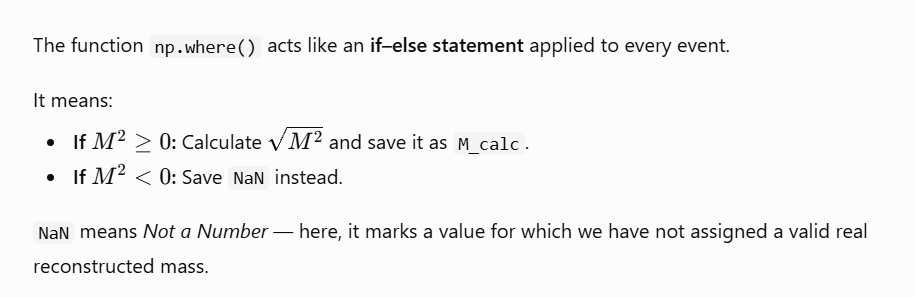

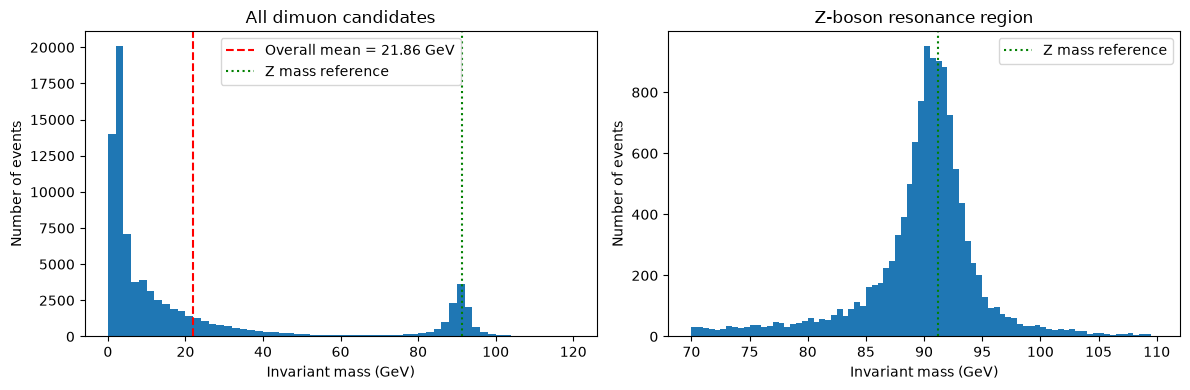

In [74]:

import numpy as np
import matplotlib.pyplot as plt

mass = df["M_calc"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Entire distribution
axes[0].hist(mass, bins=np.arange(0, 122, 2))
axes[0].axvline(
    mass.mean(), color="red", linestyle="--",
    label=f"Overall mean = {mass.mean():.2f} GeV"
)
axes[0].axvline(
    91.1879, color="green", linestyle=":",
    label="Z mass reference"
)
axes[0].set_title("All dimuon candidates")
axes[0].set_xlabel("Invariant mass (GeV)")
axes[0].set_ylabel("Number of events")
axes[0].legend()

# Zoom on Z resonance
axes[1].hist(
    mass, bins=np.arange(70, 110.5, 0.5)
)
axes[1].axvline(
    91.1879, color="green", linestyle=":",
    label="Z mass reference"
)
axes[1].set_title("Z-boson resonance region")
axes[1].set_xlabel("Invariant mass (GeV)")
axes[1].set_ylabel("Number of events")
axes[1].legend()

plt.tight_layout()
plt.show()


In [30]:
#
# Compare reconstructed masses with CERN values

df["M_diff"] = abs(df["M_calc"] - df["M"])

print("Mass reconstruction differences:")
print(df["M_diff"].describe())

print("\nFirst five events:")
display(
    df[["M", "M_calc", "M_diff"]].head()
)


Mass reconstruction differences:
count    8.375500e+04
mean     5.021618e-02
std      1.181789e+00
min      3.144638e-07
25%      1.799942e-03
50%      7.770554e-03
75%      1.787418e-02
max      1.841723e+02
Name: M_diff, dtype: float64

First five events:


,M,M_calc,M_diff
0,2.1330,2.145853,0.012853
1,13.6786,13.680958,0.002358
2,4.3813,4.395351,0.014051
3,3.2587,3.273007,0.014307
4,4.0171,4.026974,0.009874


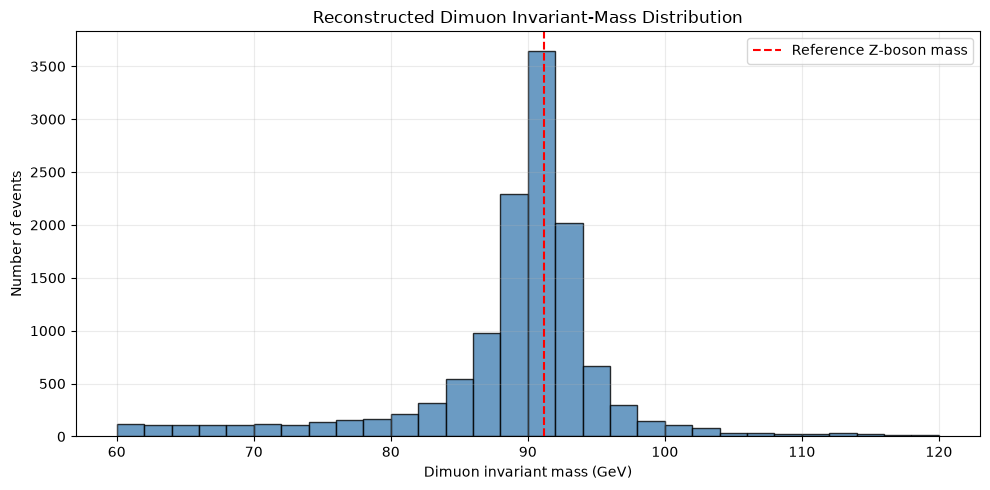

In [32]:
#Plot first invariant-mass histogram

# Select finite reconstructed masses
valid_mass = df["M_calc"].dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    valid_mass,
    bins=np.arange(60, 122, 2),
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Number of events")
plt.title("Reconstructed Dimuon Invariant-Mass Distribution")

plt.axvline(
    91.1879,
    color="red",
    linestyle="--",
    label="Reference Z-boson mass"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()



### 6. Dimuon Invariant-Mass Reconstruction

**Objective:** Independently reconstruct the invariant mass
of each muon pair using the recorded four-momenta.

**Method:** The energies and Cartesian momentum components
of both muons were combined using the relativistic
invariant-mass equation:

$$
M_{\mu\mu}^2 =
(E_1+E_2)^2
-(p_{x1}+p_{x2})^2
-(p_{y1}+p_{y2})^2
-(p_{z1}+p_{z2})^2
$$

Natural units ($c=1$) were used. CERN's supplied invariant
mass column (`M`) was not used in the reconstruction.
It was retained for comparison.

**Results:**

- Total dimuon events: **83,761**
- Events with valid, nonnegative reconstructed mass-squared:
  **83,755**
- Events with negative reconstructed mass-squared: **6**
- Mean reconstructed dimuon mass: **21.864 GeV**
- Median reconstructed dimuon mass: **6.277 GeV**
- Mean absolute difference from CERN reference: **0.05022 GeV**
- Median absolute difference from CERN reference: **0.00777 GeV**
- Maximum absolute difference: **184.17 GeV**

**Observations:**

The reconstructed dimuon invariant masses cover a broad
range, with many events at low masses and a distinct
resonance peak near 91 GeV, consistent with Z-boson
production.

The overall mean mass of 21.864 GeV is much lower than
the Z-boson mass because the dataset contains many
low-mass dimuon candidates from other processes.

Most reconstructed masses agree reasonably closely with
the CERN-provided values, but some events show large
discrepancies. Six events produced negative mass-squared
values and were marked as `NaN` rather than assigned
artificial masses.

**Conclusion:**

The Cartesian four-momentum reconstruction successfully
revealed the Z-resonance region. However, the large
discrepancies in some events require further validation
of the recorded kinematic variables.

**Next step:** Investigate mass-reconstruction discrepancies
and compare alternative reconstruction methods before
selecting the final baseline for Z-resonance fitting.


## 7. Validation of Reconstructed Invariant Mass

The reconstructed invariant masses are compared with the
reference masses supplied in the CERN dataset.

This assessment investigates numerical agreement, identifies
large discrepancies and examines whether they are associated
with previously observed momentum inconsistencies.

No additional event-selection cuts are applied at this stage.

In [77]:
#Identify large mass difference

# Mass reconstruction validation

valid_mass = df["M_calc"].notna() & df["M"].notna() #selects events where both masses are available.

# Absolute difference
df["M_diff"] = abs(df["M_calc"] - df["M"])

# Exploratory discrepancy threshold
mass_tolerance = 0.1  # GeV

large_mass_diff = valid_mass & (df["M_diff"] > mass_tolerance)
print("Events with valid mass comparisons:", valid_mass.sum())
print("Events with mass difference > 0.1 GeV:",large_mass_diff.sum())
print("Percentage of valid comparisons affected:",
      round(
          100 * large_mass_diff.sum() / valid_mass.sum(),
          3
      ), "%")

print("\nLargest mass discrepancies:")

display(
    df.loc[
        valid_mass,
        ["Run", "Event", "M", "M_calc",
         "M_diff", "pt1_diff", "pt2_diff"]
    ].nlargest(10, "M_diff")
)


Events with valid mass comparisons: 83755
Events with mass difference > 0.1 GeV: 2396
Percentage of valid comparisons affected: 2.861 %

Largest mass discrepancies:


,Run,Event,M,M_calc,M_diff,pt1_diff,pt2_diff
12724,166950,1034799867,39.1660,223.338319,184.172319,560.244211,0.000087
15178,171897,344584652,208.2520,55.919448,152.332552,242.811488,0.000088
81932,163738,123780029,100.4650,19.197481,81.267519,762.036111,0.000019
13062,166950,1050544228,84.0967,9.563390,74.533310,1164.475878,0.000055
71705,172791,771674212,87.1045,20.117174,66.987326,255.119144,0.000075
41984,166782,468415562,91.7024,27.438671,64.263729,233.852032,0.000071
39104,167043,138663868,97.8704,38.583828,59.286572,39.577183,0.000066
64768,171178,57001878,75.3566,17.291090,58.065510,265.346185,0.000003
2248,173661,37624329,92.8629,35.280268,57.582632,122.303042,0.000057
79739,165514,199444356,72.4538,16.121768,56.332032,71.537859,0.000016


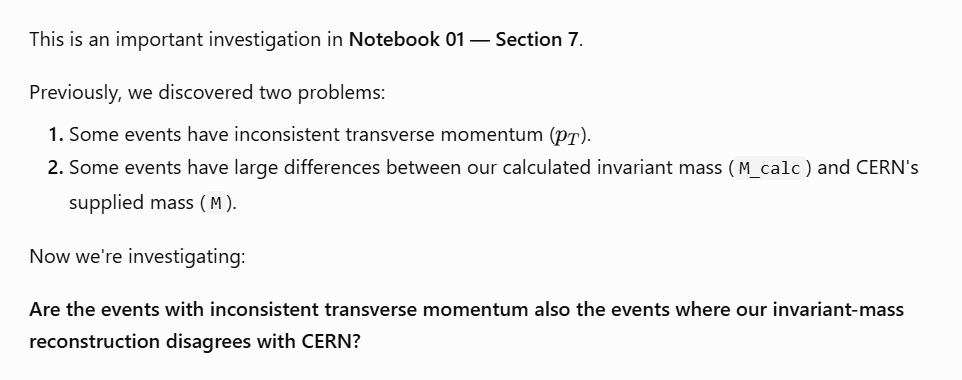

In [81]:

# Compare the two types of discrepancies
#identify events with a transverse-momentum discrepancy:
#n event is flagged if either muon has a transverse-momentum discrepancy greater than 0.01 GeV
bad_pt = ((df["pt1_diff"] > 0.01) |(df["pt2_diff"] > 0.01))
comparison = pd.crosstab( #counts events belonging to different combinations of two conditions.
    bad_pt[valid_mass],
    large_mass_diff[valid_mass],
    rownames=["pT discrepancy > 0.01 GeV"],  
    colnames=["Mass discrepancy > 0.1 GeV"]
)

display(comparison)

# Compare mass errors between groups
print("\nMedian mass difference:")

print("Events without pT discrepancy:",
      df.loc[valid_mass & ~bad_pt, "M_diff"].median())

print("Events with pT discrepancy:",
      df.loc[valid_mass & bad_pt, "M_diff"].median())


Mass discrepancy > 0.1 GeV,False,True
pT discrepancy > 0.01 GeV,,
False,79204,427
True,2155,1969



Median mass difference:
Events without pT discrepancy: 0.006810580260378174
Events with pT discrepancy: 0.09154362855393794


Events with inconsistent transverse momentum tend to have much larger differences between our reconstructed mass and CERN's supplied mass.

In [44]:

# Investigate negative invariant mass squared

negative_events = df.loc[
    mass_squared < 0,
    ["Run", "Event", "E1", "E2",
     "px1", "py1", "pz1",
     "px2", "py2", "pz2", "M"]
].copy()

negative_events["M_squared_calc"] = (
    mass_squared[mass_squared < 0]
)

display(negative_events)

print("\nNegative mass-squared summary:")
print(negative_events["M_squared_calc"].describe())


,Run,Event,E1,E2,px1,py1,pz1,px2,py2,pz2,M,M_squared_calc
17168,163387,56653962,28.1336,178.9150,-23.4886,-5.1568,-14.6008,-149.7520,-32.2654,-92.4341,0.3064,-0.073597
36571,163296,188362345,83.9271,163.2190,17.5786,27.7389,-77.2353,34.1018,53.5040,-150.3830,0.3468,-0.168294
45299,172255,14124685,103.9170,68.1158,-0.3859,-21.5211,101.6640,-0.0035,-13.9154,66.6792,0.3915,-0.045875
48298,172400,609370400,46.9487,466.1290,0.5530,38.3808,-27.0328,4.1889,382.3310,-266.6130,0.8076,-0.033895
60578,171050,755346558,82.5110,2843.7700,-20.7744,2.2763,-79.8204,-715.4210,80.9392,-2751.1200,0.4345,-11.543813
67041,172014,279755908,59.3947,3768.6800,14.1457,-35.1433,-45.7446,891.8220,-2209.9200,-2919.5700,3.3712,-21.462643



Negative mass-squared summary:
count     6.000000
mean     -5.554686
std       9.042283
min     -21.462643
25%      -8.699933
50%      -0.120946
75%      -0.052806
max      -0.033895
Name: M_squared_calc, dtype: float64


### 7. Initial Invariant-Mass Reconstruction

**Date:** 16 November 2026

**Objective:** Independently reconstruct the invariant masses of dimuon pairs and identify the Z-boson resonance.

**Method:** The recorded energies and Cartesian momentum components of both muons were combined using the relativistic invariant-mass equation. CERN's reference mass column was excluded from the calculation and reserved for validation.

**Results:**
- Total events: 83,761
- Events with nonnegative reconstructed mass-squared: 83,755
- Events with negative reconstructed mass-squared: 6
- Mean reconstructed dimuon mass: 21.864 GeV
- Median reconstructed dimuon mass: 6.277 GeV
- Median absolute difference from CERN reference: 0.00777 GeV
- Maximum absolute difference: 184.17 GeV

**Observations:** The reconstructed invariant-mass histogram showed a pronounced resonance near 91 GeV, consistent with the expected Z-boson resonance region. The full sample contained a broad distribution of lower-mass dimuon events, so its overall mean does not represent the Z-boson mass.

Although most reconstructed masses agreed closely with the CERN reference values, some large discrepancies were observed. These require further investigation before establishing the final event-selection and fitting procedures.

**Scientific decision:** No additional events were excluded solely because of disagreements with the reference mass. The six events with negative reconstructed mass-squared were assigned undefined reconstructed masses and will be examined separately.

**Next step:** Quantify large mass discrepancies, investigate their relationship with transverse momentum inconsistencies, and examine events with negative mass-squared before proceeding to resonance fitting.


## 8. Alternative Invariant-Mass Reconstruction

The invariant mass is independently reconstructed from
transverse momentum, pseudorapidity and azimuthal angle.

This provides a cross-check against the Cartesian
four-momentum calculation and CERN's reference mass.

No events are excluded based on the comparison.

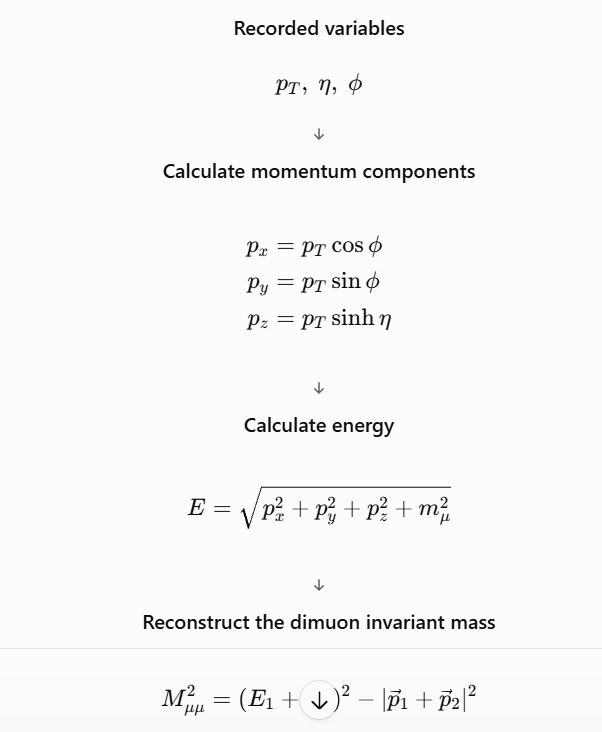

In [48]:

# Alternative invariant-mass reconstruction
# using pT, eta and phi

muon_mass = 0.105658  # GeV, natural units

# Transverse masses
mt1 = np.sqrt(df["pt1"]**2 + muon_mass**2)
mt2 = np.sqrt(df["pt2"]**2 + muon_mass**2)

# Angular differences
delta_eta = df["eta1"] - df["eta2"]
delta_phi = df["phi1"] - df["phi2"]

# Dimuon invariant mass squared
M2_alt = (
    2 * muon_mass**2
    + 2 * (
        mt1 * mt2 * np.cosh(delta_eta)
        - df["pt1"] * df["pt2"] * np.cos(delta_phi)
    )
)

# Preserve invalid results as NaN
df["M_alt"] = np.sqrt(M2_alt.where(M2_alt >= 0))

# Compare both methods with CERN reference
df["M_alt_diff"] = abs(df["M_alt"] - df["M"])

print("Cartesian reconstruction:")
print(df["M_diff"].describe())

print("\nAlternative reconstruction:")
print(df["M_alt_diff"].describe())

print("\nFirst five events:")
display(
    df[["M", "M_calc", "M_alt",
        "M_diff", "M_alt_diff"]].head()
)


Cartesian reconstruction:
count    8.375500e+04
mean     5.021618e-02
std      1.181789e+00
min      3.144638e-07
25%      1.799942e-03
50%      7.770554e-03
75%      1.787418e-02
max      1.841723e+02
Name: M_diff, dtype: float64

Alternative reconstruction:
count    8.376100e+04
mean     1.690480e-02
std      1.930125e-02
min      1.148278e-08
25%      3.674252e-03
50%      1.217575e-02
75%      2.212872e-02
max      3.420601e-01
Name: M_alt_diff, dtype: float64

First five events:


,M,M_calc,M_alt,M_diff,M_alt_diff
0,2.1330,2.145853,2.147729,0.012853,0.014729
1,13.6786,13.680958,13.684637,0.002358,0.006037
2,4.3813,4.395351,4.395436,0.014051,0.014136
3,3.2587,3.273007,3.280393,0.014307,0.021693
4,4.0171,4.026974,4.049695,0.009874,0.032595


In [85]:
import numpy as np
import matplotlib.pyplot as plt

# ====== CHANGE ONLY IF YOUR COLUMN NAMES ARE DIFFERENT ======
REF_COL = "M"          # CERN/reference dimuon mass
CART_COL = "M_calc"    # Cartesian reconstruction
ALT_COL = "M_alt"      # pT-eta-phi reconstruction  <-- change if needed
# ============================================================

# Keep only needed columns
cmp = df[[REF_COL, CART_COL, ALT_COL]].copy()

# Remove inf values if any
cmp = cmp.replace([np.inf, -np.inf], np.nan)

# Absolute errors relative to reference mass
cmp["cart_err"] = (cmp[CART_COL] - cmp[REF_COL]).abs()
cmp["alt_err"]  = (cmp[ALT_COL]  - cmp[REF_COL]).abs()

cart_valid = cmp["cart_err"].dropna()
alt_valid  = cmp["alt_err"].dropna()

print("Cartesian")
print("Valid comparisons:", len(cart_valid))
print("Median error (GeV):", cart_valid.median())
print("90th percentile (GeV):", cart_valid.quantile(0.90))
print("Errors > 0.1 GeV:", (cart_valid > 0.1).sum())

print("\npT-eta-phi")
print("Valid comparisons:", len(alt_valid))
print("Median error (GeV):", alt_valid.median())
print("90th percentile (GeV):", alt_valid.quantile(0.90))
print("Errors > 0.1 GeV:", (alt_valid > 0.1).sum())

Cartesian
Valid comparisons: 83755
Median error (GeV): 0.007770553834731242
90th percentile (GeV): 0.03318476356820846
Errors > 0.1 GeV: 2396

pT-eta-phi
Valid comparisons: 83761
Median error (GeV): 0.012175753890955932
90th percentile (GeV): 0.03828398036439706
Errors > 0.1 GeV: 577


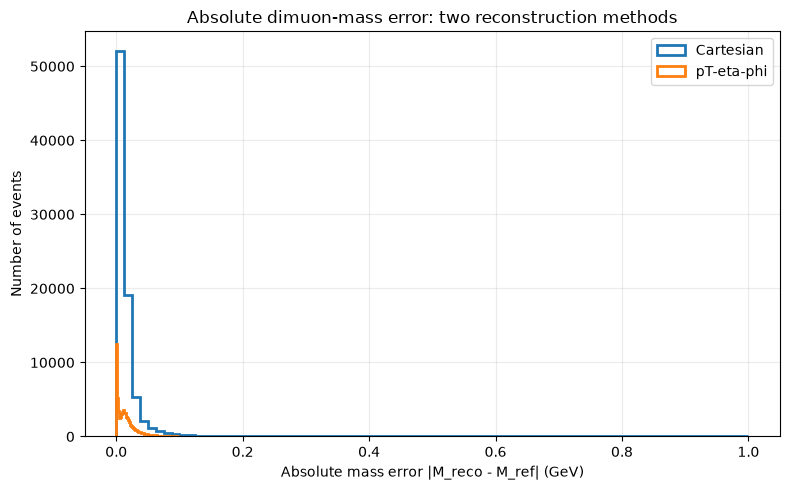

In [91]:
plt.figure(figsize=(8,5))

plt.hist(cart_valid, bins=80, range=(0, 1), histtype="step", #change 0.2 to 0.1
         linewidth=2, label="Cartesian")
plt.hist(alt_valid, bins=80, range=(0, 0.1), histtype="step",
         linewidth=2, label="pT-eta-phi")

plt.xlabel("Absolute mass error |M_reco - M_ref| (GeV)")
plt.ylabel("Number of events")
plt.title("Absolute dimuon-mass error: two reconstruction methods")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The Cartesian reconstruction gives slightly smaller typical mass errors, but the pT–eta–phi reconstruction is much more robust because it produces far fewer large discrepancies. Therefore, the alternative reconstruction appears more stable overall, especially against extreme outliers.

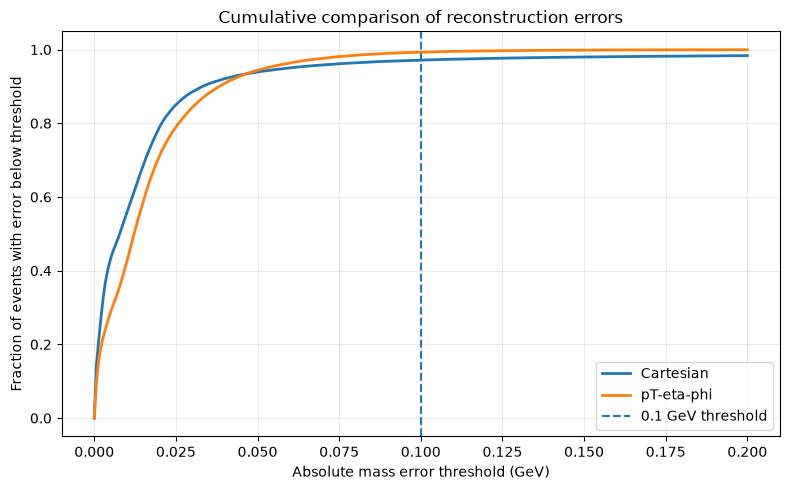

In [93]:
thresholds = np.linspace(0, 0.2, 300)

cart_cdf = [np.mean(cart_valid <= t) for t in thresholds]
alt_cdf  = [np.mean(alt_valid  <= t) for t in thresholds]

plt.figure(figsize=(8,5))
plt.plot(thresholds, cart_cdf, label="Cartesian", linewidth=2)
plt.plot(thresholds, alt_cdf, label="pT-eta-phi", linewidth=2)

plt.axvline(0.1, linestyle="--", linewidth=1.5, label="0.1 GeV threshold")

plt.xlabel("Absolute mass error threshold (GeV)")
plt.ylabel("Fraction of events with error below threshold")
plt.title("Cumulative comparison of reconstruction errors")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

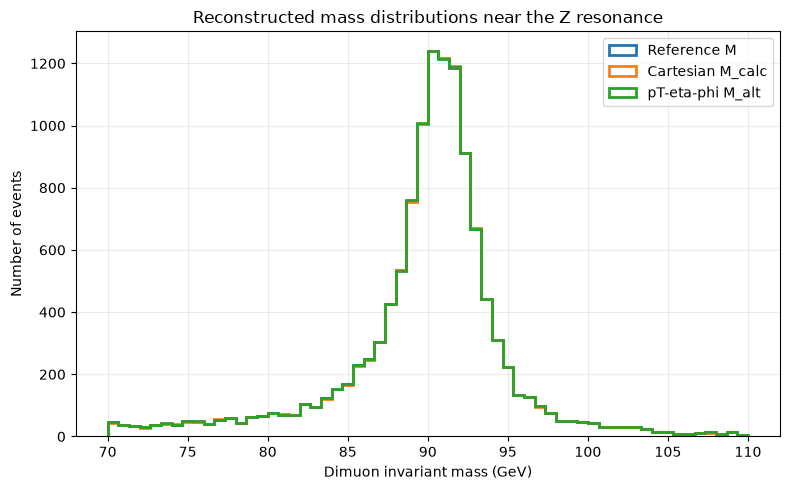

In [95]:
zmask = cmp[REF_COL].between(70, 110)

plt.figure(figsize=(8,5))

plt.hist(cmp.loc[zmask, REF_COL].dropna(), bins=60, range=(70,110),
         histtype="step", linewidth=2, label="Reference M")
plt.hist(cmp.loc[zmask, CART_COL].dropna(), bins=60, range=(70,110),
         histtype="step", linewidth=2, label="Cartesian M_calc")
plt.hist(cmp.loc[zmask, ALT_COL].dropna(), bins=60, range=(70,110),
         histtype="step", linewidth=2, label="pT-eta-phi M_alt")

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Number of events")
plt.title("Reconstructed mass distributions near the Z resonance")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

he Cartesian reconstruction gives slightly smaller typical deviations from the reference mass, but it produces many more large-error outliers. The pT–eta–phi reconstruction has slightly worse central accuracy but is much more robust, with far fewer discrepancies larger than 0.1 GeV.

In [50]:
#compare 2 reconstruction methods

# Compare agreement with CERN reference

methods = {
    "Cartesian": "M_diff",
    "pT-eta-phi": "M_alt_diff"
}

for name, column in methods.items():
    errors = df[column].dropna()

    print(f"\n{name}")
    print("Valid comparisons:", len(errors))
    print("Median error (GeV):", errors.median())
    print("90th percentile (GeV):",
          errors.quantile(0.90))
    print("Errors > 0.1 GeV:",
          (errors > 0.1).sum())



Cartesian
Valid comparisons: 83755
Median error (GeV): 0.007770553834731242
90th percentile (GeV): 0.03318476356820846
Errors > 0.1 GeV: 2396

pT-eta-phi
Valid comparisons: 83761
Median error (GeV): 0.012175753890955932
90th percentile (GeV): 0.03828398036439706
Errors > 0.1 GeV: 577


In [53]:

# Exact reconstruction from pT, eta and phi
# Treat eta as pseudorapidity, not rapidity.

muon_mass = 0.105658  # GeV

for i in [1, 2]:
    pt = df[f"pt{i}"]
    eta = df[f"eta{i}"]
    phi = df[f"phi{i}"]

    df[f"px{i}_alt"] = pt * np.cos(phi)
    df[f"py{i}_alt"] = pt * np.sin(phi)
    df[f"pz{i}_alt"] = pt * np.sinh(eta)

    p2 = (
        df[f"px{i}_alt"]**2
        + df[f"py{i}_alt"]**2
        + df[f"pz{i}_alt"]**2
    )

    df[f"E{i}_alt"] = np.sqrt(
        p2 + muon_mass**2
    )

E_sum = df["E1_alt"] + df["E2_alt"]

px_sum = df["px1_alt"] + df["px2_alt"]
py_sum = df["py1_alt"] + df["py2_alt"]
pz_sum = df["pz1_alt"] + df["pz2_alt"]

M2_corrected = (
    E_sum**2
    - px_sum**2
    - py_sum**2
    - pz_sum**2
)

# Preserve negative or non-finite values as missing
M2_corrected = M2_corrected.where(
    np.isfinite(M2_corrected) & (M2_corrected >= 0)
)

df["M_alt_corrected"] = np.sqrt(M2_corrected)

df["M_alt_corrected_diff"] = abs(
    df["M_alt_corrected"] - df["M"]
)

print("Corrected alternative reconstruction:")
print(df["M_alt_corrected_diff"].describe())

print("\nNumber of errors > 0.1 GeV:")
print((df["M_alt_corrected_diff"] > 0.1).sum())

print("\nFirst five events:")
display(
    df[[
        "M",
        "M_calc",
        "M_alt_corrected",
        "M_diff",
        "M_alt_corrected_diff"
    ]].head()
)


Corrected alternative reconstruction:
count    8.376100e+04
mean     1.162471e-02
std      1.572942e-02
min      1.862473e-08
25%      1.849913e-03
50%      6.647831e-03
75%      1.627337e-02
max      3.524717e-01
Name: M_alt_corrected_diff, dtype: float64

Number of errors > 0.1 GeV:
326

First five events:


,M,M_calc,M_alt_corrected,M_diff,M_alt_corrected_diff
0,2.1330,2.145853,2.147495,0.012853,0.014495
1,13.6786,13.680958,13.680827,0.002358,0.002227
2,4.3813,4.395351,4.396042,0.014051,0.014742
3,3.2587,3.273007,3.275025,0.014307,0.016325
4,4.0171,4.026974,4.026392,0.009874,0.009292


### 8. Comparison of Invariant-Mass Reconstruction Methods

**Date:** 16 November 2026

Two methods were investigated for calculating dimuon invariant mass: direct combination of Cartesian four-momentum components and an alternative reconstruction using transverse momentum, pseudorapidity and azimuthal angle.

The Cartesian method produced a median absolute difference of 0.00777 GeV relative to CERN's supplied invariant mass, but 2,396 events exceeded a 0.1 GeV difference.

The initial alternative method produced a median difference of 0.01218 GeV, with 577 events exceeding 0.1 GeV. However, its energy representation required correction because pseudorapidity and rapidity are not identical for massive particles.

A revised reconstruction using the full Cartesian momentum components derived from \(p_T,\eta,\phi\) and the muon rest mass will be evaluated before selecting the baseline method.

**Scientific decision:** No reconstruction method has yet been adopted as the definitive baseline. No additional events were removed during this comparison.

**Next step:** Complete the corrected kinematic reconstruction, validate the results against CERN's reference values, and proceed to resonance fitting.


In [56]:

# Save reconstructed masses and quality diagnostics

output_file = RESULTS_DIR / "dimuon_reconstructed.csv"

columns_to_save = [
    "Run", "Event",
    "Q1", "Q2",
    "pt1", "eta1", "phi1",
    "pt2", "eta2", "phi2",
    "M",
    "M_calc",
    "M_alt_corrected",
    "M_diff",
    "M_alt_corrected_diff",
    "pt1_diff",
    "pt2_diff"
]

df[columns_to_save].to_csv(
    output_file,
    index=False
)

print("Saved analysis data to:", output_file)
print("Number of rows:", len(df))


Saved analysis data to: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\results\dimuon_reconstructed.csv
Number of rows: 83761
